# BHARATH BUILDS
## 21 DAYS TO ML ENGINEER

# DAY 14 — K-MEANS CLUSTERING

**Learning Track:** Machine Learning  
**Topic:** Unsupervised Learning — K-Means Clustering  
**Dataset:** Mall Customer Segmentation (`Mall_Customers.csv`)  
**Implementation Environment:** Python, Google Colab, Scikit-learn

---

## 1. Objective

The objective of this practical session is to understand and implement K-Means Clustering, an unsupervised machine learning algorithm that discovers groups of similar data points without predefined target labels.

This session focuses on selecting relevant customer features, applying feature scaling, comparing different values of K, evaluating clustering quality, visualizing customer segments, and interpreting the resulting clusters using evidence from the dataset.

By the end of this session, the goal is to build a reproducible customer segmentation workflow and understand how clustering can support exploratory data analysis and business understanding.

## 2. Theoretical Concepts Covered

### 2.1 Supervised vs. Unsupervised Learning

- Understand the difference between supervised and unsupervised learning.
- Understand how unsupervised learning discovers patterns without predefined target labels.
- Identify K-Means as an unsupervised clustering algorithm.

### 2.2 Working Principle of K-Means

- Understand the role of K, the number of clusters.
- Understand centroid initialization and assignment of points to the nearest centroid.
- Understand centroid updates and iterative convergence.
- Learn the purpose of K-Means++ initialization and multiple initializations using `n_init`.

### 2.3 Centroids, Distance, and Feature Scaling

- Understand centroids as the mean positions of points assigned to clusters.
- Understand Euclidean distance and its role in cluster assignment.
- Learn why features with different numerical ranges should be scaled.
- Understand the use of `StandardScaler` before fitting K-Means.

### 2.4 Inertia and Choosing the Number of Clusters

- Understand inertia as the sum of squared distances between data points and their assigned centroids.
- Learn the Elbow Method for comparing different K values.
- Understand the Silhouette Score as an additional measure of cluster separation.
- Learn why K should not be selected using inertia alone.

### 2.5 Cluster Interpretation

- Visualize clusters using selected numerical features.
- Compare cluster-level averages and medians.
- Interpret cluster profiles using observed data patterns.
- Understand why cluster IDs are arbitrary labels rather than predefined business categories.

### 2.6 Limitations of K-Means

- The number of clusters must be selected before model fitting.
- Results are sensitive to feature scaling, outliers, and centroid initialization.
- K-Means works best with compact, approximately spherical clusters.
- Irregular cluster shapes and clusters with different densities can be difficult to identify.

## 3. Practical Concepts to Be Implemented

The following workflow will be implemented step by step in Google Colab.

1. Import the required Python libraries.
2. Load the Mall Customer Segmentation dataset.
3. Inspect the dataset structure, selected columns, data types, and missing values.
4. Select relevant clustering features.
5. Exclude `CustomerID` because it is an identifier rather than a behavioral feature.
6. Apply `StandardScaler` to the selected features.
7. Fit K-Means models for multiple K values and record inertia.
8. Plot the Elbow Curve to examine how inertia changes with K.
9. Calculate and compare Silhouette Scores for candidate K values.
10. Select a reasonable K based on evaluation results and interpretability.
11. Fit the final K-Means model and assign cluster labels.
12. Visualize customer clusters and centroids using the original feature values.
13. Compare cluster averages and medians to understand customer profiles.
14. Document findings, observations, and limitations.
15. Review key machine learning interview questions related to K-Means.

**Important:** K = 5 will be used initially as a teaching example. The final choice should be reviewed against the actual Elbow Curve, Silhouette Scores, visualization, and interpretability.

## 4. Dataset Description

**Dataset Name:** Mall Customer Segmentation  
**File Name:** `Mall_Customers.csv`

The dataset contains customer information that can be used to demonstrate unsupervised learning through customer segmentation.

For this practical, the selected features are:

| Feature | Description |
|---|---|
| `Annual Income (k$)` | Customer's annual income, expressed in thousands of dollars |
| `Spending Score (1-100)` | Customer spending score on a scale from 1 to 100 |
| `CustomerID` | Customer identifier; excluded from clustering features |

The practical will use annual income and spending score to discover groups of customers with similar feature patterns.

The dataset does not provide predefined cluster labels for this exercise. The clusters will be generated by K-Means based on the selected features.

**Dataset Source:**  
https://github.com/abcom-mltutorials/mall

**Direct CSV:**  
https://raw.githubusercontent.com/abcom-mltutorials/mall/main/Mall_Customers.csv

## 5. Libraries and Tools

The following Python libraries will be used:

- **Pandas:** Dataset loading, feature selection, and cluster profiling.
- **Matplotlib:** Visualizing the Elbow Curve and customer clusters.
- **Scikit-learn `KMeans`:** Building the clustering model.
- **Scikit-learn `StandardScaler`:** Scaling the selected numerical features.
- **Scikit-learn `silhouette_score`:** Evaluating cluster separation.

## 6. Expected Learning Outcomes

After completing this practical, the learner should be able to:

- Explain how K-Means clustering works.
- Distinguish supervised learning from unsupervised learning.
- Explain centroids, Euclidean distance, and inertia.
- Apply feature scaling before distance-based clustering.
- Compare candidate K values using the Elbow Method and Silhouette Score.
- Fit a K-Means model and visualize the resulting clusters.
- Interpret cluster profiles using actual dataset values.
- Identify important limitations of K-Means.
- Build a reproducible clustering experiment suitable for a machine learning portfolio.

## 7. Interview Preparation

The following questions will be reviewed at the end of the session:

1. What is K-Means Clustering?
2. Why is feature scaling important for K-Means?
3. What is a centroid?
4. What does inertia measure?
5. How can we choose a reasonable value of K?
6. What is the Silhouette Score?
7. Why are cluster IDs arbitrary?
8. What are the main limitations of K-Means?

## 8. Project Deliverable

The final deliverable is a reproducible Google Colab notebook that includes dataset preparation, feature scaling, comparison across K values, Elbow Curve analysis, Silhouette Score evaluation, cluster visualization, cluster profiling, and evidence-based interpretation.

The notebook will document not only how the model is implemented, but also why each step is necessary and what the results indicate.

## 9. Learning Workflow

**EXPLAIN → IMPLEMENT → INTERPRET → DOCUMENT → COMMIT**

This workflow emphasizes understanding the algorithm, implementing it correctly, interpreting results using evidence, documenting observations, and committing the completed work to GitHub.

---

**Bharath Builds | Day 14 — K-Means Clustering**  
*21 Days to ML Engineer Series*


step1: import libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

step 2 : load the dataset

In [ ]:
DATA_URL="https://raw.githubusercontent.com/abcom-mltutorials/mall/main/Mall_Customers.csv"

df=pd.read_csv(DATA_URL)
print("data loaded successfully")
print("Dataset shape:",df.shape)

data loaded successfully
Dataset shape: (200, 5)


In [ ]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


step3: select features


In [ ]:
features_columns=["Annual Income (k$)",	"Spending Score (1-100)"]

X=df[features_columns].copy()

print("selected features:",features_columns)

print(X.isnull().sum())

selected features: ['Annual Income (k$)', 'Spending Score (1-100)']
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Step 4 — Feature Scaling Using StandardScaler

In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print("first 5 scaled rows")
print(X_scaled[:5])

first 5 scaled rows
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


step5 : elbow method to find suitable K

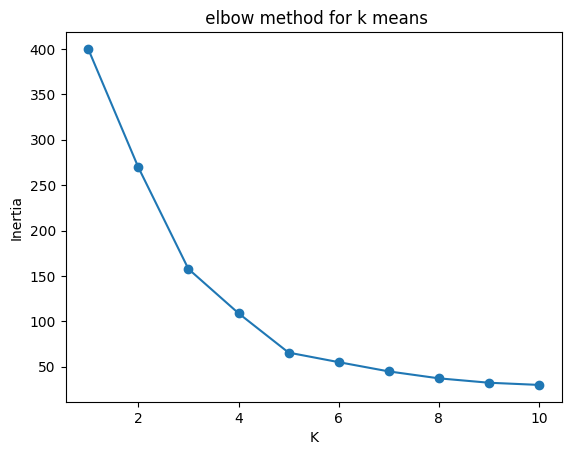

In [ ]:
k_values=range(1,11)

inertias=[]

for k in k_values:
  model=KMeans(n_clusters=k,random_state=42,n_init=10,init="k-means++")
  model.fit(X_scaled)
  inertias.append(model.inertia_)

plt.plot(k_values,inertias,marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title(" elbow method for k means")
plt.show()

step 6: evaluate cluster using silhoustte score

,K,Silhouette Score
0,5,0.554657
1,6,0.539880
2,7,0.528149
3,4,0.493907
4,3,0.466585
5,9,0.457085
6,8,0.455215
7,10,0.443171
8,2,0.321271


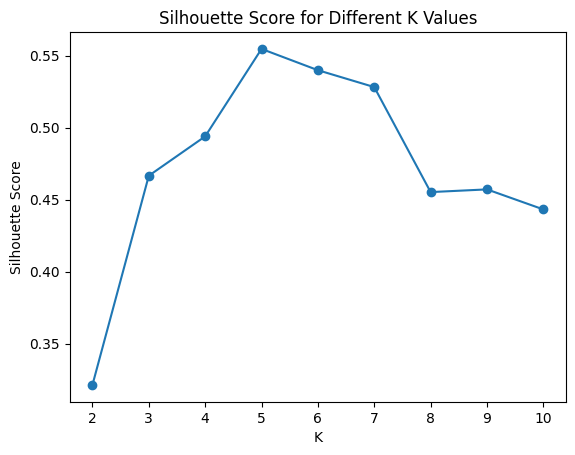

In [ ]:
silhouette_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })


silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        by="Silhouette Score",
        ascending=False
    ).reset_index(drop=True)
)

# plotting
plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.show()

step 7: train the final k values

In [ ]:
selected_k=5
kmeans=KMeans(n_clusters=selected_k,init="k-means++",n_init=10,random_state=42)
df["Cluster"]=kmeans.fit_predict(X_scaled)

print("selected k value:",selected_k)
print("silhouste_score:",round(silhouette_score(X_scaled,df["Cluster"]),3))

display(df[features_columns + ["Cluster"]].head())


selected k value: 5
silhouste_score: 0.555


,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


Step 8 — Visualize Clusters and Centroids

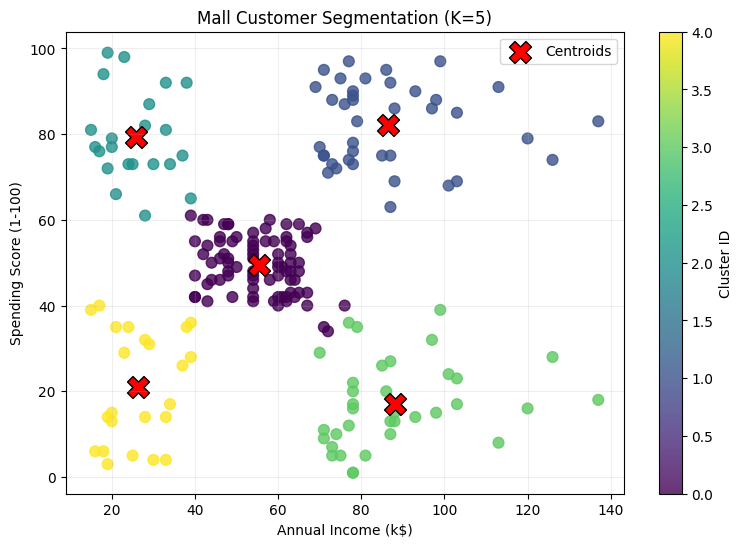

In [ ]:
centroids_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=60,
    alpha=0.8
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker="X",
    s=250,
    c="red",
    edgecolor="black",
    label="Centroids"
)

plt.title(
    f"Mall Customer Segmentation (K={selected_k})"
)

plt.xlabel("Annual Income (k$)")

plt.ylabel("Spending Score (1-100)")

plt.legend()

plt.colorbar(scatter, label="Cluster ID")

plt.grid(True, alpha=0.2)

plt.show()

step 9 : interpret the customer cluster

In [ ]:
cluster_profile=(df.groupby("Cluster")[features_columns].agg(['count',"mean","median"]).round(2))
display(cluster_profile)

Annual Income (k$)               Spending Score (1-100)              
                     count   mean median                  count   mean median
Cluster                                                                      
0                       81  55.30   54.0                     81  49.52   50.0
1                       39  86.54   79.0                     39  82.13   83.0
2                       22  25.73   24.5                     22  79.36   77.0
3                       35  88.20   85.0                     35  17.11   16.0
4                       23  26.30   25.0                     23  20.91   17.0

Step 10  Document the Findings

In [ ]:
for cluster_id, row in df.groupby("Cluster")[features_columns].mean().iterrows():

    print(
        f"Cluster {cluster_id}: "
        f"Average Annual Income = "
        f"{row['Annual Income (k$)']:.1f} k$, "
        f"Average Spending Score = "
        f"{row['Spending Score (1-100)']:.1f}"
    )

    print("K-Means Model Summary")

print("----------------------")

print("Selected K:", selected_k)

print("Number of Customers:", len(df))

print("Number of Clusters:", df["Cluster"].nunique())

print(
    "Final Silhouette Score:",
    round(
        silhouette_score(X_scaled, df["Cluster"]),
        3
    )
)

print("\nCluster Distribution:")

print(df["Cluster"].value_counts().sort_index())

Cluster 0: Average Annual Income = 55.3 k$, Average Spending Score = 49.5
K-Means Model Summary
Cluster 1: Average Annual Income = 86.5 k$, Average Spending Score = 82.1
K-Means Model Summary
Cluster 2: Average Annual Income = 25.7 k$, Average Spending Score = 79.4
K-Means Model Summary
Cluster 3: Average Annual Income = 88.2 k$, Average Spending Score = 17.1
K-Means Model Summary
Cluster 4: Average Annual Income = 26.3 k$, Average Spending Score = 20.9
K-Means Model Summary
----------------------
Selected K: 5
Number of Customers: 200
Number of Clusters: 5
Final Silhouette Score: 0.555

Cluster Distribution:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


Key Interpretations and Observations
1. The K-Means algorithm successfully grouped 200 customers into 5 clusters based on Annual Income and Spending Score.

2. Cluster 0 is the largest group, with 81 customers showing relatively average income and spending behaviour.

3. Cluster 1 represents high-income customers with high spending scores, while Cluster 2 represents lower-income customers with high spending scores.

4. Cluster 3 shows that higher income does not necessarily mean higher spending. These customers have high income but relatively low spending scores.

5. Cluster 4 represents customers with relatively low income and low spending scores.

6. The final Silhouette Score of 0.555 indicates reasonably separated clusters. Overall, the results demonstrate how unsupervised learning can identify meaningful customer patterns without predefined labels.